# Guia de Fontes da Unifesspa: análise temática dos perfis (conjunto de demonstração)

**AVISO: os 30 perfis analisados aqui são FICTÍCIOS.** Eles foram inventados para testar o método e não descrevem docentes da Unifesspa. Os resultados abaixo mostram se a técnica funciona e quais são seus limites. Eles **não** descrevem o acervo real de fontes.

**O que este caderno faz**

1. Lê os perfis do conjunto de demonstração.
2. Limpa os textos (pré-processamento): minúsculas, sem acentos, sem palavras vazias (como "de", "para") e com radicais (por exemplo, "mineração" e "mineral" viram "miner").
3. Transforma cada perfil em números com **TF-IDF**: palavras que aparecem em poucos perfis pesam mais do que palavras que aparecem em todos.
4. Agrupa perfis parecidos com **K-Means** e mede a qualidade dos grupos com o **índice de silhueta** (de -1 a 1; quanto mais perto de 1, mais separados e coesos os grupos).
5. Mostra os temas de cada grupo e a cobertura por campus.

In [1]:
# Instalação e dados de apoio (no Colab o nltk já vem instalado)
import nltk
nltk.download('rslp', quiet=True)
nltk.download('stopwords', quiet=True)

True

In [2]:
import json, os, re, unicodedata, urllib.request
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.metrics import silhouette_score, adjusted_rand_score
from nltk.corpus import stopwords
from nltk.stem import RSLPStemmer

os.makedirs('figuras', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
AZUL, CINZA = '#1f6feb', '#6b756f'
SEMENTE = 42   # semente fixa: o resultado se repete a cada execução

## 1. Dados

Os perfis ficam no repositório público do projeto, em `dados/demo/docentes-demo.json`. Cada perfil tem resumo, temas, formações, campus e formatos de atendimento. O campo `unidade` **não** entra na análise, porque ele traz o nome da área e entregaria a resposta ao método.

In [3]:
URL = 'https://raw.githubusercontent.com/unifesspa-ascom/fontes/main/dados/demo/docentes-demo.json'
LOCAL = os.environ.get('DEMO_LOCAL')   # caminho alternativo, se não houver internet
if LOCAL:
    bruto = json.load(open(LOCAL, encoding='utf-8'))
else:
    bruto = json.load(urllib.request.urlopen(URL))

assert bruto.get('ficticio') is True, 'O arquivo deveria ser o conjunto FICTÍCIO'
df = pd.DataFrame(bruto['docentes'])
df['area'] = df['unidade'].str.replace('Unidade de demonstração: ', '', regex=False)   # só para conferência no fim
df['texto'] = df.apply(lambda r: ' '.join([r['resumo'], ' '.join(r['temas']),
                                           ' '.join(f['curso'] for f in r['formacoes'])]), axis=1)
print(len(df), 'perfis FICTÍCIOS')
print(df['campus'].value_counts().to_string())

30 perfis FICTÍCIOS
campus
Marabá (Campus Sede)    13
Canaã dos Carajás        5
Xinguara                 4
Rondon do Pará           3
São Félix do Xingu       3
Santana do Araguaia      2


## 2. Pré-processamento

Para cada perfil: minúsculas, sem acentos, só letras, sem palavras vazias e com radicais (algoritmo RSLP, feito para o português). Guardamos também a palavra original mais frequente de cada radical, só para os gráficos ficarem legíveis.

In [4]:
stem = RSLPStemmer()
def sem_acento(s): return unicodedata.normalize('NFD', s).encode('ascii', 'ignore').decode().lower()
vazias = {sem_acento(w) for w in stopwords.words('portuguese')}

original_de = {}          # radical -> contagem de formas originais
def preparar(texto):
    saida = []
    for w in re.findall(r'[a-z]+', sem_acento(texto)):
        if w in vazias or len(w) <= 2: continue
        r = stem.stem(w)
        original_de.setdefault(r, Counter())[w] += 1
        saida.append(r)
    return saida

df['tokens'] = df['texto'].apply(preparar)
rotulo = {r: c.most_common(1)[0][0] for r, c in original_de.items()}
print(df.loc[0, 'texto'][:160], '...')
print(df.loc[0, 'tokens'][:12])

Epidemiologia de doenças transmitidas por mosquitos na Amazônia, com foco em dengue, malária e febre amarela. Analisa a relação entre chuvas, desmatamento e cas ...
['epidemiolog', 'doenc', 'transmit', 'mosquit', 'amazon', 'foc', 'deng', 'mal', 'febr', 'amarel', 'analis', 'relaca']


## 3. TF-IDF

Mantemos só os radicais que aparecem em pelo menos 2 perfis (`min_df=2`): um radical que aparece em um único perfil não ajuda a comparar perfis entre si. Usamos `sublinear_tf` para que repetir uma palavra muitas vezes não domine o peso.

In [5]:
vec = TfidfVectorizer(analyzer=lambda x: x, min_df=2, sublinear_tf=True)
X = vec.fit_transform(df['tokens'])
termos = np.array(vec.get_feature_names_out())
print('matriz perfis x radicais:', X.shape)

matriz perfis x radicais: (30, 88)


## 4. Quantos grupos? K-Means e índice de silhueta

Testamos de 2 a 10 grupos. Para cada número de grupos, repetimos o K-Means com 10 sementes diferentes e ficamos com a melhor silhueta. Atenção: **a silhueta aqui é baixa** (veja o gráfico). Isso significa que os grupos se sobrepõem. Com poucos perfis e textos curtos, isso é esperado, e o resultado deve ser lido como indício, não como prova.

 k  silhueta
 2     0.030
 3     0.038
 4     0.046
 5     0.061
 6     0.076
 7     0.090
 8     0.111
 9     0.116
10     0.120


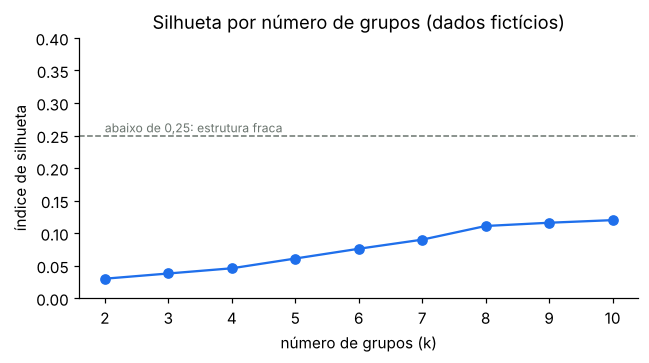

In [6]:
def melhor_kmeans(M, k, sementes=range(10)):
    melhor = None
    for s in sementes:
        km = KMeans(k, n_init=10, random_state=s).fit(M)
        sil = silhouette_score(M, km.labels_)
        if melhor is None or sil > melhor[0]: melhor = (sil, km)
    return melhor

ks = list(range(2, 11))
res = {k: melhor_kmeans(X, k) for k in ks}
tab_k = pd.DataFrame({'k': ks, 'silhueta': [round(res[k][0], 3) for k in ks]})
print(tab_k.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(tab_k['k'], tab_k['silhueta'], marker='o', color=AZUL)
ax.axhline(0.25, ls='--', color=CINZA, lw=1); ax.text(2, 0.255, 'abaixo de 0,25: estrutura fraca', color=CINZA, fontsize=8)
ax.set_ylim(0, 0.4); ax.set_xlabel('número de grupos (k)'); ax.set_ylabel('índice de silhueta')
ax.set_title('Silhueta por número de grupos (dados fictícios)')
fig.tight_layout(); fig.savefig('figuras/1_silhueta_por_k.png'); plt.show()

A silhueta cresce com o número de grupos e quase se estabiliza em 9 e 10 (0,116 e 0,120), sempre abaixo de 0,25. Escolhemos **k = 9**, o menor valor dentro desse patamar (menos grupos são mais fáceis de a ASCOM revisar). É uma escolha de bom senso, e não uma separação nítida dos dados.

In [7]:
K = 9
sil, km = res[K]
df['grupo'] = km.labels_ + 1
print('k =', K, '| silhueta =', round(sil, 3))
print(df['grupo'].value_counts().sort_index().to_string())

k = 9 | silhueta = 0.116
grupo
1    4
2    3
3    3
4    4
5    3
6    4
7    3
8    4
9    2


## 5. Do que fala cada grupo

Para cada grupo, mostramos os radicais com maior peso médio no TF-IDF (escritos pela forma original mais comum) e quem está nele.

In [8]:
def termos_do_grupo(g, n=6):
    idx = np.where(df['grupo'].values == g)[0]
    media = np.asarray(X[idx].mean(axis=0)).ravel()
    top = media.argsort()[::-1][:n]
    return [(rotulo.get(termos[i], termos[i]), media[i]) for i in top]

linhas = []
for g in sorted(df['grupo'].unique()):
    membros = df[df['grupo'] == g]
    area_dom = membros['area'].value_counts()
    linhas.append({'grupo': g, 'perfis': len(membros),
                   'termos principais': ', '.join(t for t, _ in termos_do_grupo(g)),
                   'área mais comum': f"{area_dom.index[0]} ({area_dom.iloc[0]} de {len(membros)})",
                   'campi': ', '.join(sorted(membros['campus'].str.replace(' (Campus Sede)', '', regex=False).unique()))})
tab_grupos = pd.DataFrame(linhas)
pd.set_option('display.max_colwidth', 120, 'display.width', 200)
print(tab_grupos.to_string(index=False))
tab_grupos.to_csv('tabela_grupos.csv', index=False, encoding='utf-8-sig')
df[['id', 'nome', 'campus', 'area', 'grupo']].sort_values(['grupo', 'nome']).to_csv('perfis_por_grupo.csv', index=False, encoding='utf-8-sig')

 grupo  perfis                                                termos principais           área mais comum                                           campi
     1       4    educacao, escolar, ensino, letramento, professores, pedagogia         Educação (4 de 4)      Marabá, Rondon do Pará, São Félix do Xingu
     2       3             engenharia, civil, construcao, residuos, alem, solar       Engenharia (3 de 3)                       Canaã dos Carajás, Marabá
     3       3     floresta, ciencias, desmatamento, manejo, amazonia, pesquisa         Biologia (2 de 3)                Marabá, Rondon do Pará, Xinguara
     4       4            pesca, recursos, aquicultura, especies, nativas, agua         Agrárias (2 de 4) Marabá, Santana do Araguaia, São Félix do Xingu
     5       3        saude, coletiva, doencas, prevencao, municipios, trabalho            Saúde (3 de 3)                       Canaã dos Carajás, Marabá
     6       4      direito, ambiental, social, tradicionais, campo, degrada

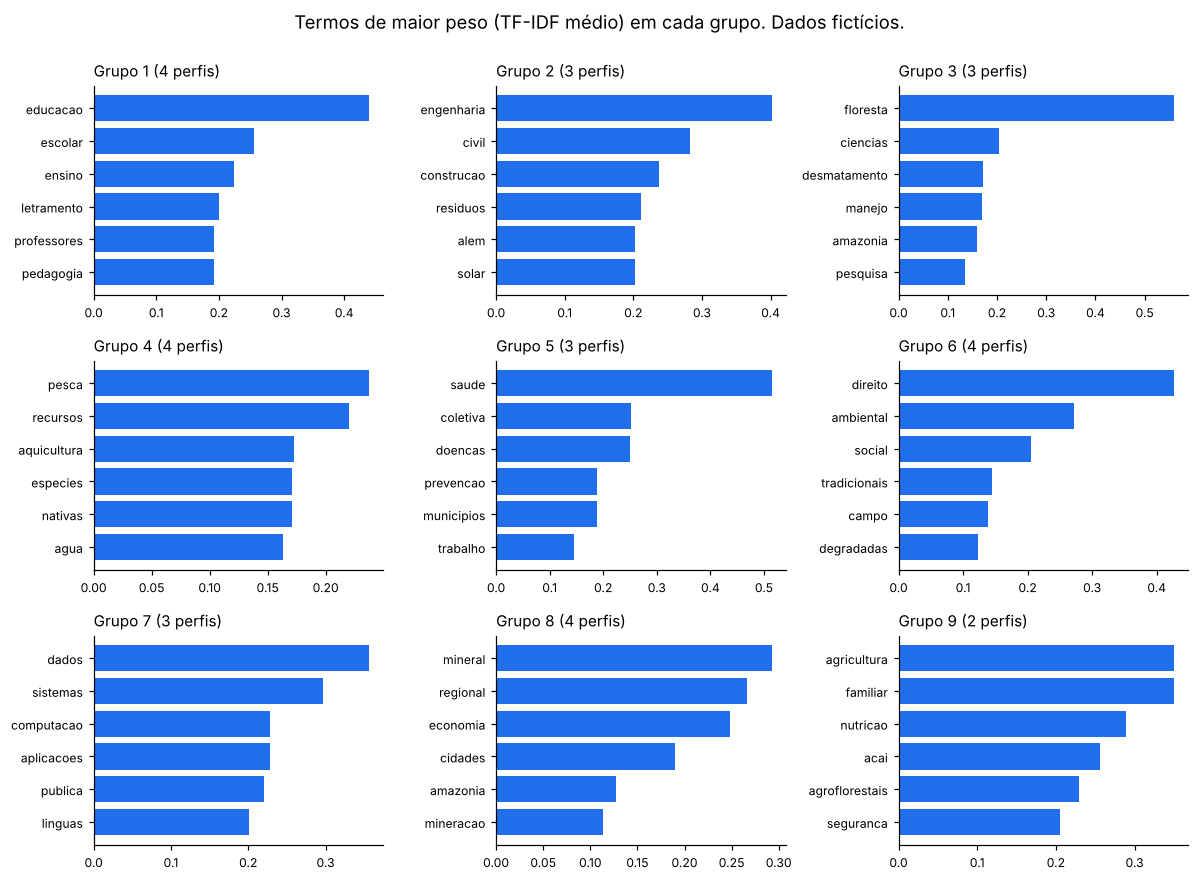

In [9]:
G = sorted(df['grupo'].unique())
fig, axs = plt.subplots(3, 3, figsize=(11, 8))
for ax, g in zip(axs.ravel(), G):
    tt = termos_do_grupo(g, 6)[::-1]
    ax.barh([t for t, _ in tt], [v for _, v in tt], color=AZUL)
    ax.set_title(f'Grupo {g} ({(df.grupo == g).sum()} perfis)', fontsize=10, loc='left')
    ax.tick_params(labelsize=8)
fig.suptitle('Termos de maior peso (TF-IDF médio) em cada grupo. Dados fictícios.', y=0.995)
fig.tight_layout(); fig.savefig('figuras/2_termos_por_grupo.png'); plt.show()

## 6. Mapa dos perfis

Para desenhar em duas dimensões, projetamos o TF-IDF com SVD (uma técnica de redução de dimensão). A projeção perde informação, então perfis próximos no desenho nem sempre estão no mesmo grupo.

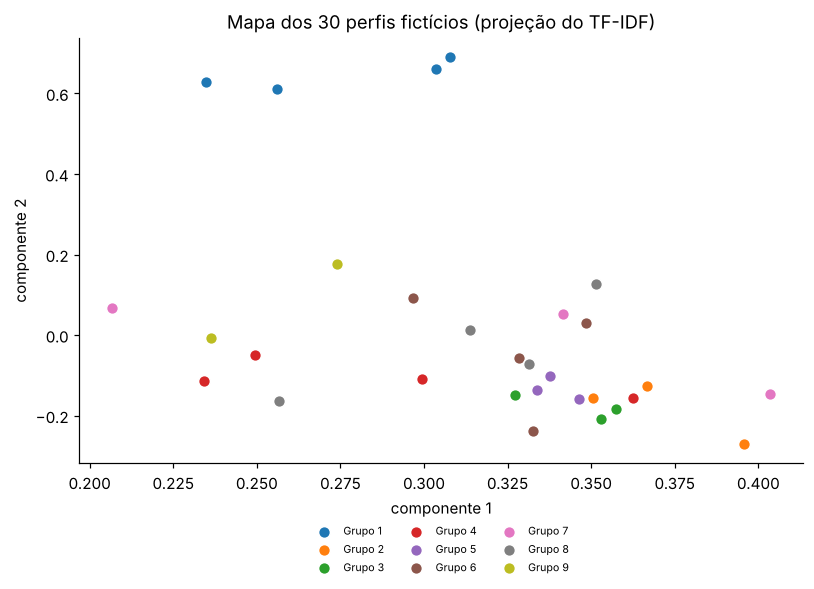

In [10]:
P = TruncatedSVD(2, random_state=SEMENTE).fit_transform(X)
cores = plt.cm.tab10(np.linspace(0, 1, 10))
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for g in G:
    m = (df['grupo'] == g).values
    ax.scatter(P[m, 0], P[m, 1], s=60, color=cores[g - 1], label=f'Grupo {g}', edgecolor='white')
ax.set_xlabel('componente 1'); ax.set_ylabel('componente 2')
ax.set_title('Mapa dos 30 perfis fictícios (projeção do TF-IDF)')
ax.legend(fontsize=7, ncol=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12))
fig.tight_layout(); fig.savefig('figuras/3_mapa_perfis.png'); plt.show()

## 7. Cobertura por campus

Aqui está a parte que interessa à curadoria da ASCOM: **em quais campi há perfis, e de quais grupos de temas.** Uma célula vazia indica um tema sem fonte naquele campus. Como os dados são fictícios, a distribuição foi inventada; o que vale é mostrar o tipo de leitura que o painel permitirá com dados reais.

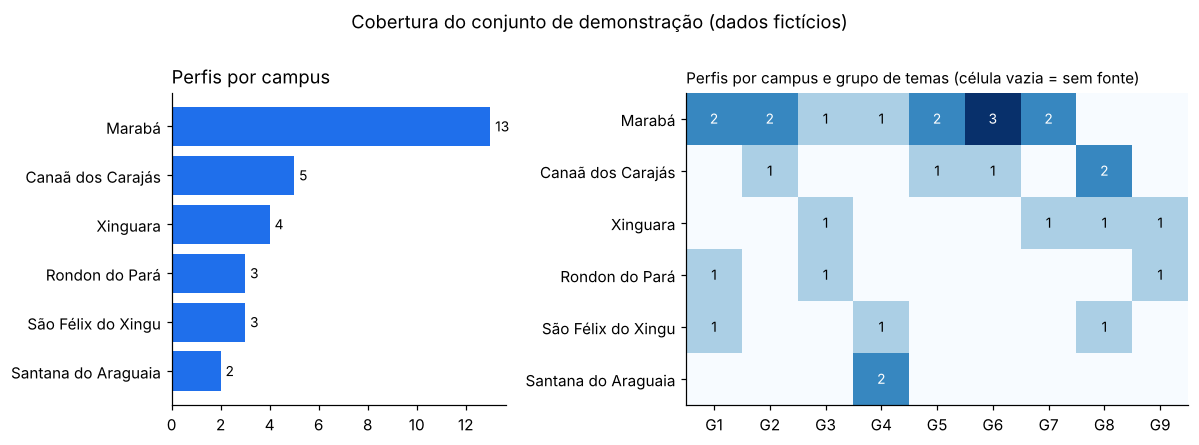

32 de 54 combinações campus x grupo sem nenhum perfil


In [11]:
df['campus_curto'] = df['campus'].str.replace(' (Campus Sede)', '', regex=False)
ordem = df['campus_curto'].value_counts().index.tolist()
cob = pd.crosstab(df['campus_curto'], df['grupo']).reindex(ordem)

fig, axs = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [1, 1.5]})
cont = df['campus_curto'].value_counts().reindex(ordem)
axs[0].barh(cont.index[::-1], cont.values[::-1], color=AZUL)
for i, v in enumerate(cont.values[::-1]): axs[0].text(v + .2, i, str(v), va='center', fontsize=9)
axs[0].set_title('Perfis por campus', loc='left')
im = axs[1].imshow(cob.values, cmap='Blues', aspect='auto', vmin=0)
axs[1].set_xticks(range(len(G))); axs[1].set_xticklabels([f'G{g}' for g in G])
axs[1].set_yticks(range(len(cob.index))); axs[1].set_yticklabels(cob.index)
for i in range(cob.shape[0]):
    for j in range(cob.shape[1]):
        v = cob.values[i, j]
        axs[1].text(j, i, v if v else '', ha='center', va='center', fontsize=9, color='white' if v >= 2 else 'black')
axs[1].set_title('Perfis por campus e grupo de temas (célula vazia = sem fonte)', loc='left', fontsize=10)
fig.suptitle('Cobertura do conjunto de demonstração (dados fictícios)', y=1.0)
fig.tight_layout(); fig.savefig('figuras/4_cobertura_por_campus.png'); plt.show()

vazios = int((cob.values == 0).sum()); print(f'{vazios} de {cob.size} combinações campus x grupo sem nenhum perfil')

## 8. Conferência: o método reencontra a estrutura que plantamos?

Como **nós mesmos inventamos** os perfis em 9 áreas, podemos comparar os grupos do K-Means com essas áreas. O índice de Rand ajustado (ARI) vale 1 quando os grupos coincidem com as áreas e perto de 0 quando a coincidência é a que se esperaria ao acaso. Esta conferência só é possível porque os dados são fictícios: com perfis reais não existe uma "resposta certa".

Também repetimos a análise de três formas diferentes, para ver se a conclusão depende das escolhas feitas. Os números de silhueta das variantes com redução de dimensão (LSA) **não são comparáveis** com os da matriz TF-IDF completa, porque a silhueta tende a subir quando se medem poucos eixos.

In [12]:
ari = adjusted_rand_score(df['area'], df['grupo'])
print('ARI (grupos x áreas inventadas), k = 9:', round(ari, 3))

def rodar(nome, tokens, min_df, lsa=None):
    v = TfidfVectorizer(analyzer=lambda x: x, min_df=min_df, sublinear_tf=True)
    M = v.fit_transform(tokens)
    if lsa: M = Normalizer().fit_transform(TruncatedSVD(lsa, random_state=SEMENTE).fit_transform(M))
    s, k9 = melhor_kmeans(M, 9)
    return {'variante': nome, 'radicais/dim.': M.shape[1], 'silhueta (k=9)': round(s, 3),
            'ARI vs áreas': round(adjusted_rand_score(df['area'], k9.labels_), 3)}

so_temas = [preparar(' '.join(t)) for t in df['temas']]
sens = pd.DataFrame([
    rodar('principal: resumo + temas + cursos, min_df=2', df['tokens'], 2),
    rodar('mesmo, min_df=1 (todos os radicais)', df['tokens'], 1),
    rodar('só os temas, min_df=1', so_temas, 1),
    rodar('principal + redução LSA (10 dim.)', df['tokens'], 2, lsa=10),
])
print(sens.to_string(index=False))
sens.to_csv('tabela_sensibilidade.csv', index=False, encoding='utf-8-sig')

ARI (grupos x áreas inventadas), k = 9: 0.477


                                    variante  radicais/dim.  silhueta (k=9)  ARI vs áreas
principal: resumo + temas + cursos, min_df=2             88           0.116         0.477
         mesmo, min_df=1 (todos os radicais)            316           0.043         0.447
                       só os temas, min_df=1            161           0.047         0.388
           principal + redução LSA (10 dim.)             10           0.420         0.507


## 9. Leitura dos resultados (para o relatório)

- **O pré-processamento e o TF-IDF funcionam**: perfis do mesmo assunto compartilham radicais (por exemplo, "pesca" e "pescado" viram o mesmo radical), e os termos de maior peso de cada grupo descrevem o assunto do grupo.
- **A separação dos grupos é fraca** (silhueta baixa), e depende das escolhas de pré-processamento. Com poucos perfis e textos curtos, é difícil esperar mais. O método não deve ser usado para decidir sozinho: a revisão da ASCOM é parte do processo.
- **O K-Means reencontra parte da estrutura planejada** (ARI de 0,48, onde 1 seria coincidência total). Educação, Computação e Saúde ficam quase inteiras em seus grupos. Já Agrárias se espalha por três grupos, Geociências e Ciências Sociais se dividem entre dois grupos (Direito e mineração/economia regional), e um perfil de Engenharia cai no grupo de pesca e recursos hídricos.
- **O que muda com dados reais**: perfis reais são mais longos e variados, o número de perfis será maior e não haverá "resposta certa". Todos os números acima devem ser refeitos com os cadastros reais, e só então descreverão o acervo.